In [1]:
import pandas as pd
import matplotlib.pyplot as plt

status = pd.read_parquet("../data/historical/station_status.parquet")

# Keep only working stations
status = status[status["is_installed"] & status["is_renting"] & (status["capacity"] > 0)]

print("Rows:", f"{len(status):,}")
print("Stations:", status["station_id"].nunique())
print("From", status["last_reported"].min(), "to", status["last_reported"].max())

Rows: 7,136,026
Stations: 115
From 2025-07-01 00:05:00+00:00 to 2026-06-30 23:55:00+00:00


In [2]:
# Work in UTC here; the clock change in October would otherwise cause errors
status["slot"] = status["last_reported"].dt.floor("15min")

grid = status.pivot_table(index="slot", columns="station_id",
                          values="num_bikes_available", aggfunc="last")

# Make sure no 15-minute slot is missing, and fill short gaps (up to 30 min)
full_index = pd.date_range(grid.index.min(), grid.index.max(), freq="15min")
grid = grid.reindex(full_index).ffill(limit=2)
grid.index.name = "slot"

print("Time slots x stations:", grid.shape)

Time slots x stations: (35040, 115)


In [3]:
HORIZON = 2  # 2 slots x 15 minutes = 30 minutes ahead
future = grid.shift(-HORIZON)

df = grid.reset_index().melt(id_vars="slot", var_name="station_id", value_name="bikes_now")
df["bikes_future"] = future.reset_index().melt(id_vars="slot")["value"].values
df = df.dropna()

# Time features, in Dublin local time, for the moment we are predicting
target_time = (df["slot"] + pd.Timedelta(minutes=30)).dt.tz_convert("Europe/Dublin")
df["hour"] = target_time.dt.hour
df["dayofweek"] = target_time.dt.dayofweek   # Monday = 0, Sunday = 6

print("Examples:", f"{len(df):,}")
df.head()

Examples: 3,856,648


,slot,station_id,bikes_now,bikes_future,hour,dayofweek
0,2025-07-01 00:00:00+00:00,1,0.0,0.0,1,1
1,2025-07-01 00:15:00+00:00,1,0.0,0.0,1,1
2,2025-07-01 00:30:00+00:00,1,0.0,0.0,2,1
3,2025-07-01 00:45:00+00:00,1,0.0,0.0,2,1
4,2025-07-01 01:00:00+00:00,1,0.0,0.0,2,1


In [4]:
split = pd.Timestamp("2026-04-01", tz="Europe/Dublin")
train = df[df["slot"] < split]
test = df[df["slot"] >= split].copy()

print("Train:", f"{len(train):,}", " Test:", f"{len(test):,}")

Train: 2,856,764  Test: 999,884


In [5]:
# Baseline 1: same as now
test["pred_same_as_now"] = test["bikes_now"]

# Baseline 2: average for this station, weekday and hour (learned from training months only)
hist = (train.groupby(["station_id", "dayofweek", "hour"])["bikes_future"]
        .mean().rename("pred_hist_avg").reset_index())
test = test.merge(hist, on=["station_id", "dayofweek", "hour"], how="left")
test["pred_hist_avg"] = test["pred_hist_avg"].fillna(test["bikes_now"])  # brand-new stations

for col in ["pred_same_as_now", "pred_hist_avg"]:
    mae = (test[col] - test["bikes_future"]).abs().mean()
    print(f"{col:18s} MAE: {mae:.2f} bikes")

pred_same_as_now   MAE: 1.06 bikes
pred_hist_avg      MAE: 5.11 bikes


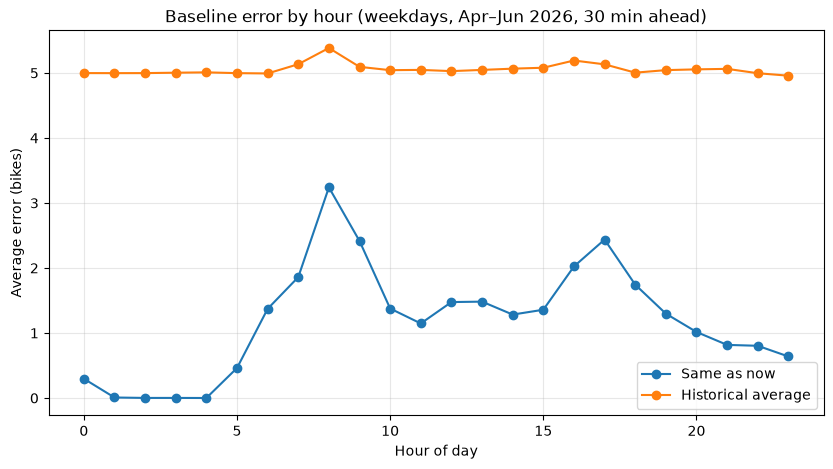

In [6]:
test["err_same_as_now"] = (test["pred_same_as_now"] - test["bikes_future"]).abs()
test["err_hist_avg"] = (test["pred_hist_avg"] - test["bikes_future"]).abs()

weekday = test[test["dayofweek"] < 5]
by_hour = weekday.groupby("hour")[["err_same_as_now", "err_hist_avg"]].mean()
by_hour.columns = ["Same as now", "Historical average"]

by_hour.plot(figsize=(10, 5), marker="o")
plt.title("Baseline error by hour (weekdays, Apr–Jun 2026, 30 min ahead)")
plt.xlabel("Hour of day")
plt.ylabel("Average error (bikes)")
plt.grid(alpha=0.3)
plt.savefig("../images/baseline_error_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
actual_empty = test["bikes_future"] == 0

for name, predicted_empty in [("Same as now", test["pred_same_as_now"] == 0),
                              ("Historical average", test["pred_hist_avg"] < 0.5)]:
    caught = (predicted_empty & actual_empty).sum()
    precision = caught / predicted_empty.sum()
    recall = caught / actual_empty.sum()
    print(f"{name:20s} precision {precision:.0%}   recall {recall:.0%}")

Same as now          precision 78%   recall 78%
Historical average   precision 80%   recall 0%


In [8]:
df.to_parquet("../data/historical/model_table.parquet", index=False)
print("Saved")

Saved


In [9]:
check = pd.DataFrame({
    "train": train.groupby("station_id")["bikes_now"].mean(),
    "test": test.groupby("station_id")["bikes_now"].mean(),
})
print("Correlation of station averages, train vs test:", round(check.corr().iloc[0, 1], 2))

Correlation of station averages, train vs test: 0.96


In [10]:
# How much does each station usually change over 30 minutes, at this weekday and hour?
train = train.assign(change=train["bikes_future"] - train["bikes_now"])
typical = (train.groupby(["station_id", "dayofweek", "hour"])["change"]
           .mean().rename("typical_change").reset_index())

test = test.merge(typical, on=["station_id", "dayofweek", "hour"], how="left")
test["typical_change"] = test["typical_change"].fillna(0)
test["pred_now_plus_change"] = (test["bikes_now"] + test["typical_change"]).clip(lower=0)

# Overall error
for col in ["pred_same_as_now", "pred_hist_avg", "pred_now_plus_change"]:
    print(f"{col:22s} MAE: {(test[col] - test['bikes_future']).abs().mean():.2f} bikes")

# Empty alerts
actual_empty = test["bikes_future"] == 0
predicted_empty = test["pred_now_plus_change"] < 0.5
caught = (predicted_empty & actual_empty).sum()
print(f"\nNow + typical change: precision {caught / predicted_empty.sum():.0%}, "
      f"recall {caught / actual_empty.sum():.0%}")

pred_same_as_now       MAE: 1.06 bikes
pred_hist_avg          MAE: 5.11 bikes
pred_now_plus_change   MAE: 1.02 bikes

Now + typical change: precision 78%, recall 78%


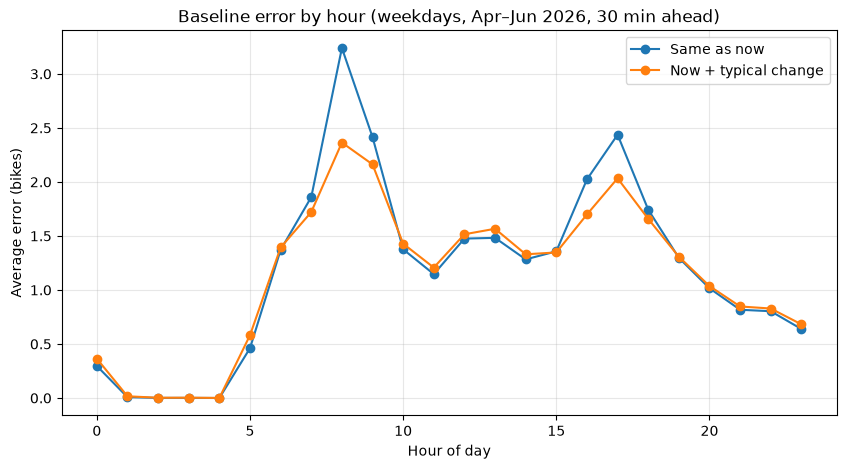

In [11]:
test["err_now_plus_change"] = (test["pred_now_plus_change"] - test["bikes_future"]).abs()

weekday = test[test["dayofweek"] < 5]
by_hour = weekday.groupby("hour")[["err_same_as_now", "err_now_plus_change"]].mean()
by_hour.columns = ["Same as now", "Now + typical change"]

by_hour.plot(figsize=(10, 5), marker="o")
plt.title("Baseline error by hour (weekdays, Apr–Jun 2026, 30 min ahead)")
plt.xlabel("Hour of day")
plt.ylabel("Average error (bikes)")
plt.grid(alpha=0.3)
plt.savefig("../images/baseline_error_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()